In [1]:
# STEP 1: Loading/importing relevant libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal, chi2_contingency,f_oneway
import seaborn as sns

pd.set_option('display.max_columns', None)

In [3]:
# loading the features dataset
features = pd.read_csv('/home/nyaugenya/dev/personal/AdvanceDataScience/Water Pump Functionality Prediction/data/features.csv')

# loading the labels dataset
labels = pd.read_csv('/home/nyaugenya/dev/personal/AdvanceDataScience/Water Pump Functionality Prediction/data/labels.csv')

In [4]:
# printing the first 5 rows of the features dataset
print("Features: ", display(features.head()))



,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,NaN,GeoData Consultants Ltd,Other,NaN,True,2010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,2009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,NaN,True,1986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,NaN,NaN,True,0,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe


Features:  None


In [5]:
# printing the first 5 rows of the labels dataset
print("Lables:",display(labels.head()))

,id,status_group
0,69572,functional
1,8776,functional
2,34310,functional
3,67743,non functional
4,19728,functional


Lables: None


In [6]:
#   STEP 2: Pre-Cleaning EDA (Exploratory Data Analysis) of the features dataset

In [7]:
def basic_checks(df):
    print("Shape of the dataset: ", df.shape)
    print("Duplicate rows in the dataset: ", df.duplicated().sum())
    print("Missing values in the dataset: \n", df.isnull().sum())
    print("Basic Information about the dataset: ", df.info())
    print("Summary Statistics(Numerical features) of the dataset: ",display(df.describe().T))
    print("\n Summary Statistics(Categorical features) of the dataset: ",display(df.describe(include=['str','object']).T))

In [8]:
basic_checks(features)

Shape of the dataset:  (59400, 40)
Duplicate rows in the dataset:  0
Missing values in the dataset: 
 id                           0
amount_tsh                   0
date_recorded                0
funder                    3637
gps_height                   0
installer                 3655
longitude                    0
latitude                     0
wpt_name                     2
num_private                  0
basin                        0
subvillage                 371
region                       0
region_code                  0
district_code                0
lga                          0
ward                         0
population                   0
public_meeting            3334
recorded_by                  0
scheme_management         3878
scheme_name              28810
permit                    3056
construction_year            0
extraction_type              0
extraction_type_group        0
extraction_type_class        0
management                   0
management_group             0

,count,mean,std,min,25%,50%,75%,max
id,59400.0,37115.131768,21453.128371,0.00000,18519.750000,37061.500000,55656.500000,7.424700e+04
amount_tsh,59400.0,317.650385,2997.574558,0.00000,0.000000,0.000000,20.000000,3.500000e+05
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
num_private,59400.0,0.474141,12.236230,0.00000,0.000000,0.000000,0.000000,1.776000e+03
region_code,59400.0,15.297003,17.587406,1.00000,5.000000,12.000000,17.000000,9.900000e+01
district_code,59400.0,5.629747,9.633649,0.00000,2.000000,3.000000,5.000000,8.000000e+01
population,59400.0,179.909983,471.482176,0.00000,0.000000,25.000000,215.000000,3.050000e+04
construction_year,59400.0,1300.652475,951.620547,0.00000,0.000000,1986.000000,2004.000000,2.013000e+03


Summary Statistics(Numerical features) of the dataset:  None


,count,unique,top,freq
date_recorded,59400,356,2011-03-15,572
funder,55763,1896,Government Of Tanzania,9084
installer,55745,2145,DWE,17402
wpt_name,59398,37399,none,3563
basin,59400,9,Lake Victoria,10248
subvillage,59029,19287,Madukani,508
region,59400,21,Iringa,5294
lga,59400,125,Njombe,2503
ward,59400,2092,Igosi,307
public_meeting,56066,2,True,51011



 Summary Statistics(Categorical features) of the dataset:  None


In [9]:
features.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
id,59400.0,37115.131768,21453.128371,0.00000,18519.750000,37061.500000,55656.500000,7.424700e+04
amount_tsh,59400.0,317.650385,2997.574558,0.00000,0.000000,0.000000,20.000000,3.500000e+05
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
num_private,59400.0,0.474141,12.236230,0.00000,0.000000,0.000000,0.000000,1.776000e+03
region_code,59400.0,15.297003,17.587406,1.00000,5.000000,12.000000,17.000000,9.900000e+01
district_code,59400.0,5.629747,9.633649,0.00000,2.000000,3.000000,5.000000,8.000000e+01
population,59400.0,179.909983,471.482176,0.00000,0.000000,25.000000,215.000000,3.050000e+04
construction_year,59400.0,1300.652475,951.620547,0.00000,0.000000,1986.000000,2004.000000,2.013000e+03


In [10]:
# convert the date recordeed and construction year to datetime format
 # error='coerce' will convert any invalid date to NaT (Not a Time) eg 32/13/2026 => NaT
features['date_recorded'] = pd.to_datetime(features['date_recorded'], errors='coerce',)# format='%Y-%m-%d')
features['construction_year'] = pd.to_datetime(features['construction_year'], errors='coerce')

In [11]:
# merge the target and the features dataset to have a complete dataset for analysis
data_df = pd.merge(features, labels, how='inner', on='id')

In [12]:
data_df.head()

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1970-01-01 00:00:00.000001999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,NaN,GeoData Consultants Ltd,Other,NaN,True,1970-01-01 00:00:00.000002010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,1970-01-01 00:00:00.000002009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,NaN,True,1970-01-01 00:00:00.000001986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,NaN,NaN,True,1970-01-01 00:00:00.000000000,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


In [13]:
data_df['status_group'].value_counts()

status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64

/tmp/ipykernel_51953/1589257953.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status_group', data=data_df, palette='colorblind')


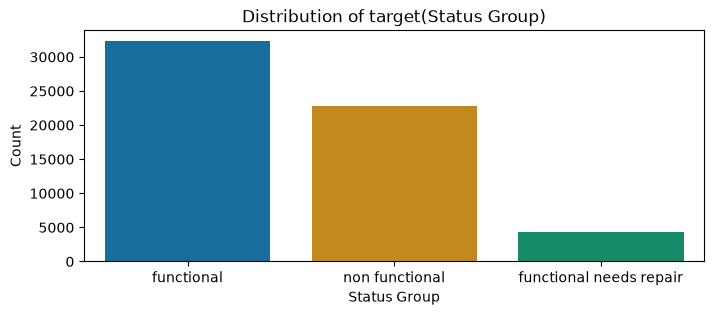

In [14]:
# Alternatively, we can use the value_counts() method to get the counts of each unique value in the 'status_group' column and then plot a bar chart using matplotlib or seaborn.

plt.figure(figsize=(8, 3))
sns.countplot(x='status_group', data=data_df, palette='colorblind')
plt.title('Distribution of target(Status Group)')
plt.xlabel('Status Group')
plt.ylabel('Count')
plt.show()



In [15]:
# Check for different categories in the categorical features and their counts

In [16]:
categorical_cols = data_df.select_dtypes(include=['object']).columns
print(categorical_cols)

for col in categorical_cols:
    print('-'*40, col.upper(), '-'*40)
    print(data_df[col].unique())
    print("\n")


Index(['funder', 'installer', 'wpt_name', 'basin', 'subvillage', 'region',
       'lga', 'ward', 'public_meeting', 'recorded_by', 'scheme_management',
       'scheme_name', 'permit', 'extraction_type', 'extraction_type_group',
       'extraction_type_class', 'management', 'management_group', 'payment',
       'payment_type', 'water_quality', 'quality_group', 'quantity',
       'quantity_group', 'source', 'source_type', 'source_class',
       'waterpoint_type', 'waterpoint_type_group', 'status_group'],
      dtype='str')
---------------------------------------- FUNDER ----------------------------------------
<StringArray>
[               'Roman',              'Grumeti',         'Lottery Club',
               'Unicef',          'Action In A',  'Mkinga Distric Coun',
                 'Dwsp',                'Rwssp',             'Wateraid',
          'Isingiro Ho',
 ...
                 'Tove',           'Nerthlands',       'Nazalet Church',
 'Scharnhorstgymnasium',       'Wanginyi Water', 

/tmp/ipykernel_51953/1289535496.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data_df.select_dtypes(include=['object']).columns


In [17]:
# select the final columns to be used for machine learning model training and testing
columns_to_keep = ['amount_tsh', 'gps_height', 'region','basin', 'region_code', 'construction_year', 'date_recorded',  'district_code', 'population', 'public_meeting', 'scheme_management', 'permit', 'extraction_type_class', 'management_group', 'payment_type', 'water_quality', 'quantity_group', 'source_type', 'waterpoint_type_group','status_group']

filtered_data_df = data_df[columns_to_keep]
filtered_data_df.shape

(59400, 20)

In [18]:
# create a new 'month' column from the 'date_recorded' column to analyze the month of data collection
filtered_data_df['month_recorded'] = filtered_data_df['date_recorded'].dt.month

In [19]:
filtered_data_df['age'] = filtered_data_df['date_recorded'].dt.year - filtered_data_df['construction_year'].dt.year

filtered_data_df.head()


,amount_tsh,gps_height,region,basin,region_code,construction_year,date_recorded,district_code,population,public_meeting,scheme_management,permit,extraction_type_class,management_group,payment_type,water_quality,quantity_group,source_type,waterpoint_type_group,status_group,month_recorded,age
0,6000.0,1390,Iringa,Lake Nyasa,11,1970-01-01 00:00:00.000001999,2011-03-14,5,109,True,VWC,False,gravity,user-group,annually,soft,enough,spring,communal standpipe,functional,3,41
1,0.0,1399,Mara,Lake Victoria,20,1970-01-01 00:00:00.000002010,2013-03-06,2,280,NaN,Other,True,gravity,user-group,never pay,soft,insufficient,rainwater harvesting,communal standpipe,functional,3,43
2,25.0,686,Manyara,Pangani,21,1970-01-01 00:00:00.000002009,2013-02-25,4,250,True,VWC,True,gravity,user-group,per bucket,soft,enough,dam,communal standpipe,functional,2,43
3,0.0,263,Mtwara,Ruvuma / Southern Coast,90,1970-01-01 00:00:00.000001986,2013-01-28,63,58,True,VWC,True,submersible,user-group,never pay,soft,dry,borehole,communal standpipe,non functional,1,43
4,0.0,0,Kagera,Lake Victoria,18,1970-01-01 00:00:00.000000000,2011-07-13,1,0,True,NaN,True,gravity,other,never pay,soft,seasonal,rainwater harvesting,communal standpipe,functional,7,41


In [20]:
# Check for the remaining nulls
# calculate the percentage of null values in each column
nulls = filtered_data_df.isnull().sum() / len(filtered_data_df) * 100

nulls

amount_tsh               0.000000
gps_height               0.000000
region                   0.000000
basin                    0.000000
region_code              0.000000
construction_year        0.000000
date_recorded            0.000000
district_code            0.000000
population               0.000000
public_meeting           5.612795
scheme_management        6.528620
permit                   5.144781
extraction_type_class    0.000000
management_group         0.000000
payment_type             0.000000
water_quality            0.000000
quantity_group           0.000000
source_type              0.000000
waterpoint_type_group    0.000000
status_group             0.000000
month_recorded           0.000000
age                      0.000000
dtype: float64

### Threshold to deal with missing values.
- 35% or above missing values in a column will be dropped
- 34& and below: 
    - (Numerical) Fill using the mean or median
    - (Categorical) Fill mode
- 0 to 5%: Drop rows with missing values. fill the nulls.

In [21]:
# Drop the rows with missing values
filtered_data_df = filtered_data_df.dropna(subset=['scheme_management','permit','public_meeting'])

### Recheck the categorical entries in the categorical columns

In [22]:
# Get the categorcal features and their unique values
categorical_cols = filtered_data_df.select_dtypes(include=['str','object']).columns.to_list()
print(categorical_cols)

# feature selection using Chi-Square test of independence to determine the relationship between categorical features and the target variable (status_group)

for col in categorical_cols:
    print('-'*40, col.upper(), '-'*40)
    print("\n")
    alpha = 0.05
    h0 = f"There is no significant relationship between {col} and its functionality status."
    h1 = f"There is a significant relationship between {col} and its functionality status."
    observed_data = pd.crosstab(filtered_data_df[col], filtered_data_df['status_group'])
    observed_data
    chi2, p, dof, expected = chi2_contingency(observed_data)
    if p < alpha:
        print(f"Reject the null hypothesis (p-value: {p}) ({h0})")
    else:
        print(f"Fail to reject the null hypothesis (p-value: {p}) ({h1})")

['region', 'basin', 'public_meeting', 'scheme_management', 'permit', 'extraction_type_class', 'management_group', 'payment_type', 'water_quality', 'quantity_group', 'source_type', 'waterpoint_type_group', 'status_group']
---------------------------------------- REGION ----------------------------------------


Reject the null hypothesis (p-value: 0.0) (There is no significant relationship between region and its functionality status.)
---------------------------------------- BASIN ----------------------------------------


Reject the null hypothesis (p-value: 0.0) (There is no significant relationship between basin and its functionality status.)
---------------------------------------- PUBLIC_MEETING ----------------------------------------


Reject the null hypothesis (p-value: 8.43172844891694e-82) (There is no significant relationship between public_meeting and its functionality status.)
---------------------------------------- SCHEME_MANAGEMENT --------------------------------------

['amount_tsh', 'gps_height', 'region_code', 'district_code', 'population']


/tmp/ipykernel_51953/3647179490.py:6: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(x='age', data=filtered_data_df, kde=True, bins=30, palette='colorblind')


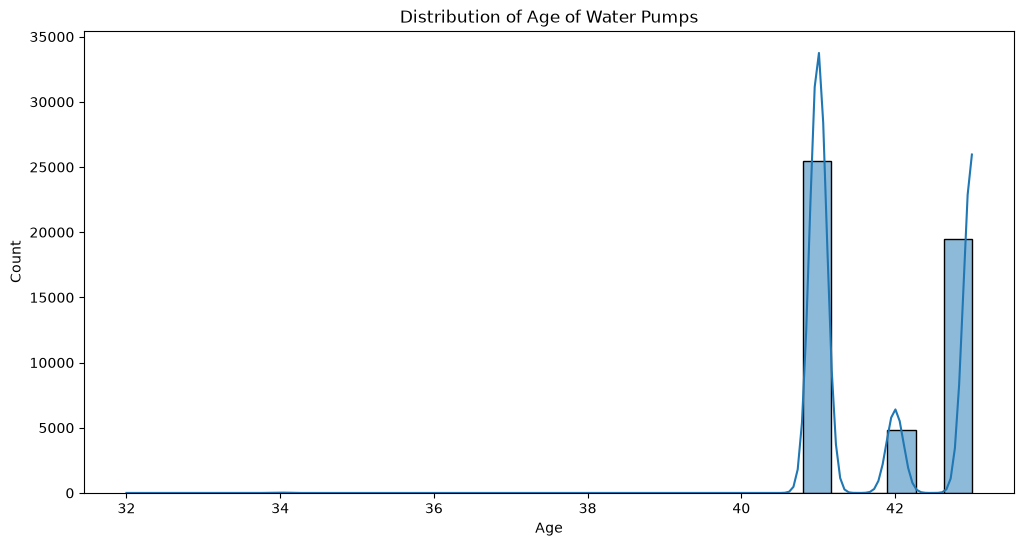

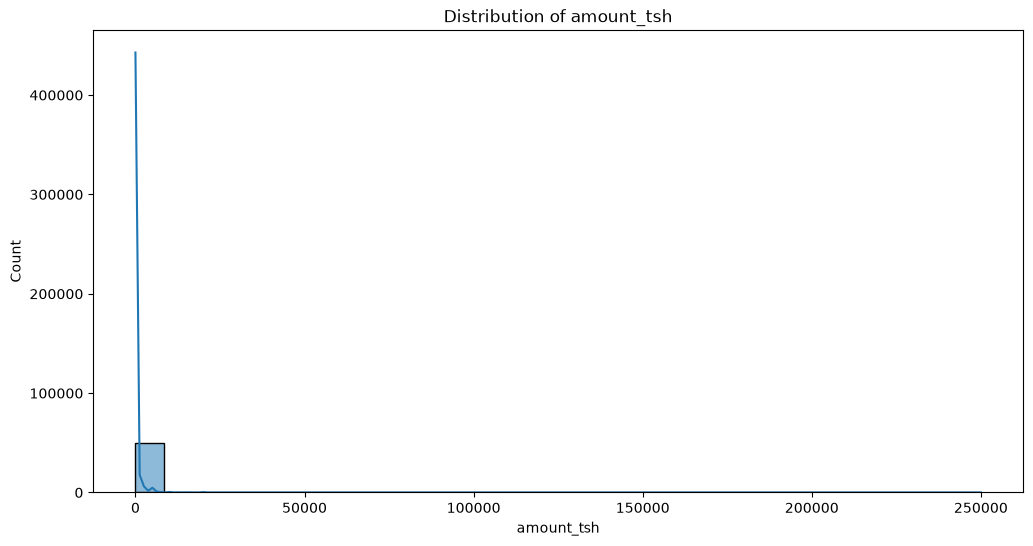

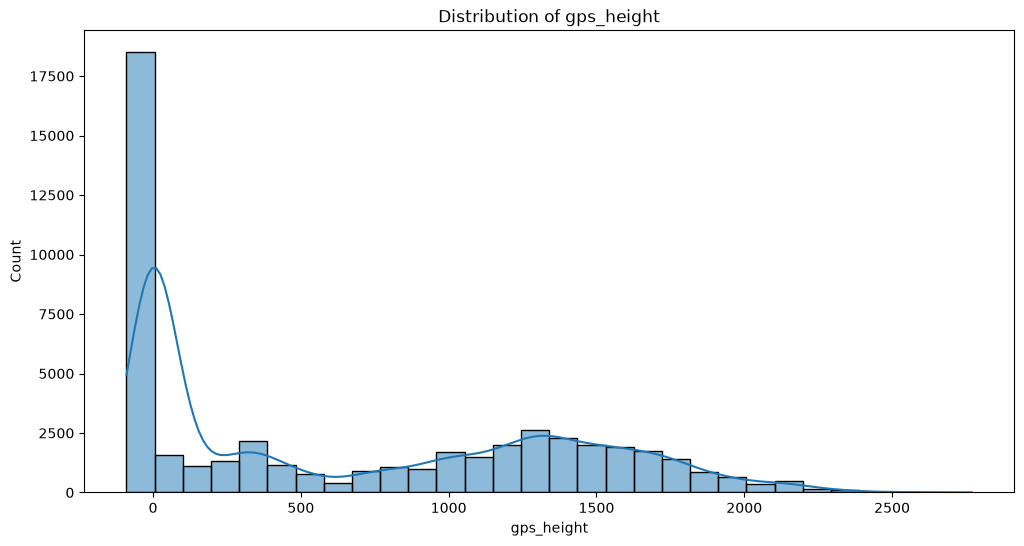

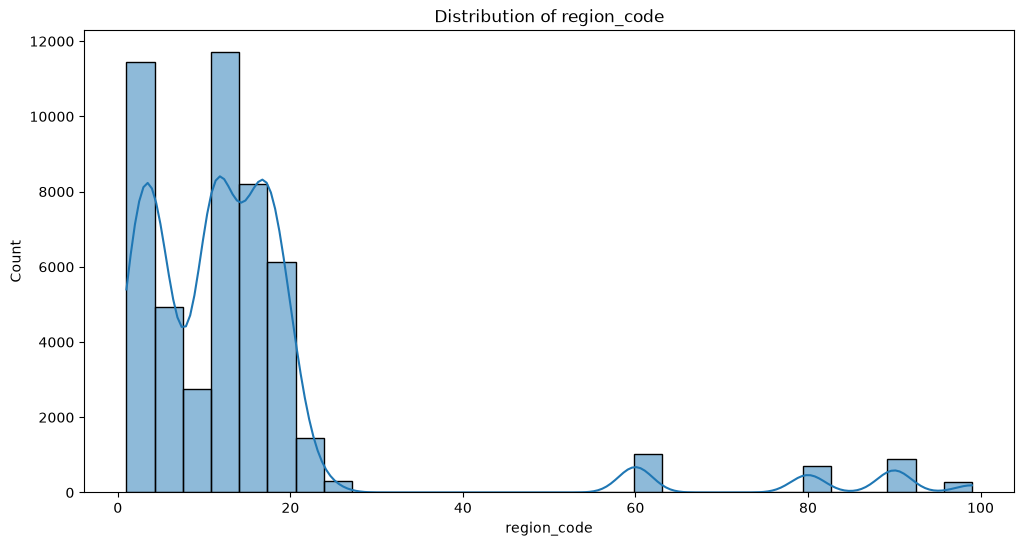

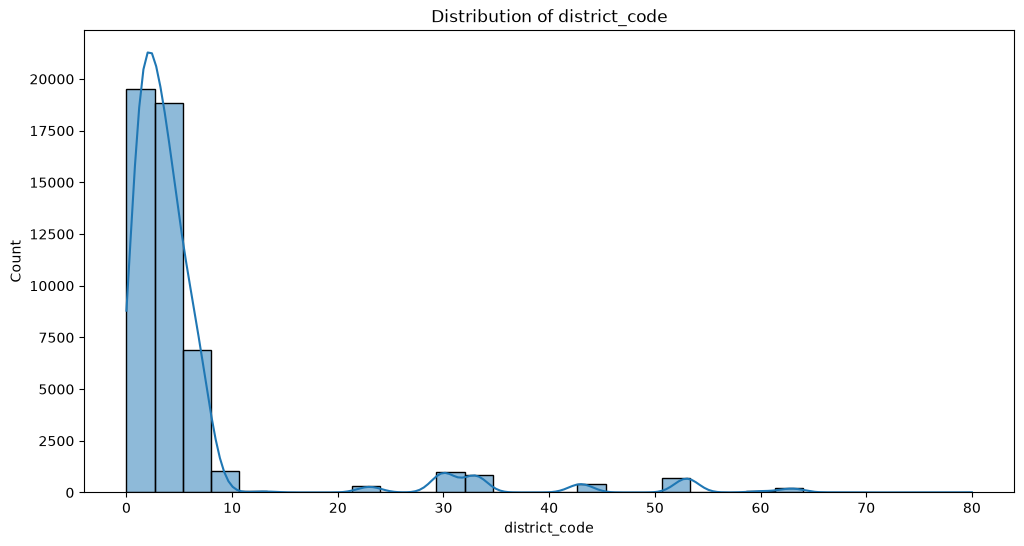

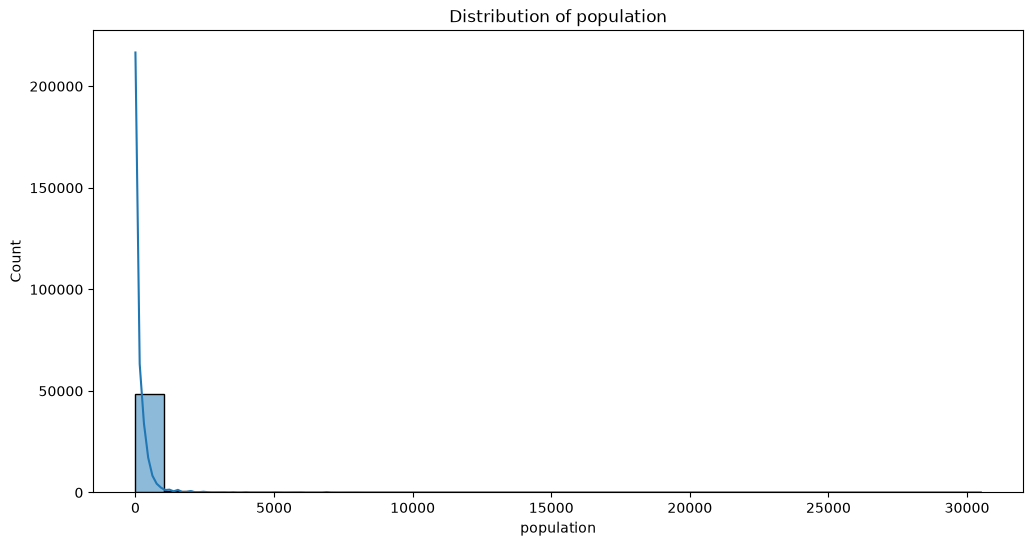

In [23]:
numerical_cols = filtered_data_df.select_dtypes(include=['int64','float64']).columns.to_list()
print(numerical_cols)

plt.figure(figsize=(12, 6))
plt.title('Distribution of Age of Water Pumps')
sns.histplot(x='age', data=filtered_data_df, kde=True, bins=30, palette='colorblind')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

for col in numerical_cols:
    plt.figure(figsize=(12, 6))
    plt.title(f'Distribution of {col}')
    sns.histplot(filtered_data_df[col], kde=True, bins=30)
    plt.xlabel(f"{col}")
    plt.ylabel('Count')
    plt.show()

In [24]:
## DISCLAIMER!! One-Way ANOVA test is used to determine if there are any statistically significant differences between the means of three or more independent (unrelated) groups. It is an extension of the t-test for independent samples, which is used to compare the means of two groups. The one-way ANOVA test is used when there is one independent variable with three or more levels (groups) and one dependent variable that is continuous.

In [25]:
# Population vs Status Group using One-Way ANOVA test
h0="the mean/average population of the different status groups are equal"
h1="the mean/average population of the different status groups are not equal"
alpha = 0.05

groups=[group['population'].values for name, group in filtered_data_df.groupby('status_group')]
stat, p = f_oneway(*groups)
print(f"F-statistic: {stat}, p-value: {p}")
if(p <= alpha):
    print(f"Reject the null hypothesis: {h0}. There is a significant difference in the mean population of the different status groups.")
else:
    print(f"Fail to reject the null hypothesis: {h0}. There is no significant difference in the mean population of the different status groups.")

F-statistic: 3.5482249579268137, p-value: 0.028782941960535567
Reject the null hypothesis: the mean/average population of the different status groups are equal. There is a significant difference in the mean population of the different status groups.


In [26]:
# Remove the spaces before and after the forward slashes in the basin classes i.e Ruvuma / Southern Coast to Ruvuma/Southern Coast

filtered_data_df['basin'] = filtered_data_df['basin'].str.replace(' / ', '/')
# OR
filtered_data_df['basin'] =  filtered_data_df['basin'].str.replace({'Wami / Ruvu': 'Wami/Ruvu'})
filtered_data_df

,amount_tsh,gps_height,region,basin,region_code,construction_year,date_recorded,district_code,population,public_meeting,scheme_management,permit,extraction_type_class,management_group,payment_type,water_quality,quantity_group,source_type,waterpoint_type_group,status_group,month_recorded,age
0,6000.0,1390,Iringa,Lake Nyasa,11,1970-01-01 00:00:00.000001999,2011-03-14,5,109,True,VWC,False,gravity,user-group,annually,soft,enough,spring,communal standpipe,functional,3,41
2,25.0,686,Manyara,Pangani,21,1970-01-01 00:00:00.000002009,2013-02-25,4,250,True,VWC,True,gravity,user-group,per bucket,soft,enough,dam,communal standpipe,functional,2,43
3,0.0,263,Mtwara,Ruvuma/Southern Coast,90,1970-01-01 00:00:00.000001986,2013-01-28,63,58,True,VWC,True,submersible,user-group,never pay,soft,dry,borehole,communal standpipe,non functional,1,43
5,20.0,0,Tanga,Pangani,4,1970-01-01 00:00:00.000002009,2011-03-13,8,1,True,VWC,True,submersible,user-group,per bucket,salty,enough,other,communal standpipe,functional,3,41
6,0.0,0,Shinyanga,Internal,17,1970-01-01 00:00:00.000000000,2012-10-01,3,0,True,VWC,True,handpump,user-group,never pay,soft,enough,borehole,hand pump,non functional,10,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59395,10.0,1210,Kilimanjaro,Pangani,3,1970-01-01 00:00:00.000001999,2013-05-03,5,125,True,Water Board,True,gravity,user-group,per bucket,soft,enough,spring,communal standpipe,functional,5,43
59396,4700.0,1212,Iringa,Rufiji,11,1970-01-01 00:00:00.000001996,2011-05-07,4,56,True,VWC,True,gravity,user-group,annually,soft,enough,river/lake,communal standpipe,functional,5,41
59397,0.0,0,Mbeya,Rufiji,12,1970-01-01 00:00:00.000000000,2011-04-11,7,0,True,VWC,False,handpump,user-group,monthly,fluoride,enough,borehole,hand pump,functional,4,41
59398,0.0,0,Dodoma,Rufiji,1,1970-01-01 00:00:00.000000000,2011-03-08,4,0,True,VWC,True,handpump,user-group,never pay,soft,insufficient,shallow well,hand pump,functional,3,41


In [27]:
# save the cleaned dataset to a new CSV file for future use
filtered_data_df.to_csv('/home/nyaugenya/dev/personal/AdvanceDataScience/Water Pump Functionality Prediction/data/cleaned_water_pump_data.csv', index=False)

In [28]:
## Hypoythesis Testing

### Null Hypothesis (H0): There is no significant relationship between the age of the water pump and its functionality status.

### Alternative Hypothesis (H1): There is a significant relationship between the age of the water pump and its functionality status.

#### steps

# Define the null and alternative hypotheses.
# Choose a significance level (alpha). 5% - 0.05
# Collect and analyze the data.
# Make a decision and interpret the results. - Z-test, T-test, Chi-square test
#   calculate the p-value and compare it to the significance level. If the p-value is less than alpha, reject the null hypothesis; otherwise, fail to reject the null hypothesis.



In [29]:
alpha = 0.05
h0 = "There is no significant relationship between the age of the water pump and its functionality status."
h1 = "There is a significant relationship between the age of the water pump and its functionality status."
observed_data = pd.crosstab(filtered_data_df['permit'], filtered_data_df['status_group'])
observed_data
chi2, p, dof, expected = chi2_contingency(observed_data)
print("p-value:", p)
print("Chi-square statistic:", chi2)
print("Expected Values:\n", pd.DataFrame(expected))
if p < alpha:
    print(f"Reject the null hypothesis (p-value: {p}) ({h0})")
else:
    print(f"Fail to reject the null hypothesis (p-value: {p}) ({h1})")

p-value: 3.566116682511604e-31
Chi-square statistic: 140.21732128614173
Expected Values:
               0            1             2
0   8733.692616  1170.340329   5993.967055
1  18646.307384  2498.659671  12797.032945
Reject the null hypothesis (p-value: 3.566116682511604e-31) (There is no significant relationship between the age of the water pump and its functionality status.)
